# Proyecto Integrador · Semana 5
## Workshops: Simulación de escenarios críticos y Sensibilidad de hiperparámetros

**Caso:** clasificar tumores como *malignos* o *benignos* con el dataset Breast Cancer Wisconsin (incluido en scikit-learn, no requiere descarga).

**Por qué este caso:** un falso negativo (no detectar un tumor maligno) es mucho más costoso que un falso positivo, así que la métrica que importa es el **recall de la clase maligna**, sin descuidar la precisión.

| Parte | Qué practicas | Concepto de la teoría |
|---|---|---|
| 0 | Baseline y evaluación con incertidumbre | Métricas básicas, evaluación estadística robusta |
| Workshop 1 | Ruido, datos faltantes, desbalance, cambio de distribución, feature caída | Generalización, validación en contextos simulados |
| Workshop 2 | Optuna, importancia, slice/contour, partial dependence | Optimización y sensibilidad de hiperparámetros |
| Cierre | Evaluación final y prueba de estrés del modelo optimizado | Validación en contextos reales |

**Cómo trabajar:** ejecuta las celdas en orden. Las celdas marcadas **TAREA** son para que las completes.

## 0. Preparación y baseline

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, average_precision_score)

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
SEED = 42

datos = load_breast_cancer(as_frame=True)
X = datos.data
y = 1 - datos.target          # 1 = maligno (clase positiva), 0 = benigno
print("Muestras y variables:", X.shape)
print("Proporción de malignos:", round(y.mean(), 3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED)

Muestras y variables: (569, 30)
Proporción de malignos: 0.373


In [ ]:
def evaluar(modelo, X, y):
    """Devuelve varias métricas para la clase positiva (maligno)."""
    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]
    return {
        "accuracy": accuracy_score(y, y_pred),
        "recall": recall_score(y, y_pred),
        "precision": precision_score(y, y_pred, zero_division=0),
        "f1": f1_score(y, y_pred),
        "auc": roc_auc_score(y, y_prob),
        "auc_pr": average_precision_score(y, y_prob),
    }


# Baseline: si el modelo no supera esto, no aporta nada
dummy = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train, y_train)

modelo = make_pipeline(StandardScaler(),
                       RandomForestClassifier(n_estimators=200, random_state=SEED))
modelo.fit(X_train, y_train)

tabla = pd.DataFrame({"dummy": evaluar(dummy, X_test, y_test),
                      "random forest": evaluar(modelo, X_test, y_test)}).T
tabla.round(3)

,accuracy,recall,precision,f1,auc,auc_pr
dummy,0.491,0.281,0.305,0.293,0.449,0.355
random forest,0.971,0.922,1.000,0.959,0.996,0.994


In [ ]:
# Evaluación robusta: validación cruzada repetida + intervalo de confianza por bootstrap
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="recall")

rng = np.random.default_rng(SEED)
boot = [rng.choice(scores, len(scores)).mean() for _ in range(2000)]
bajo, alto = np.percentile(boot, [2.5, 97.5])
print(f"Recall (CV 5x3) = {scores.mean():.3f} ± {scores.std():.3f}   IC95% = [{bajo:.3f}, {alto:.3f}]")

Recall (CV 5x3) = 0.925 ± 0.059   IC95% = [0.896, 0.955]


---
# Workshop 1 · Simulación de escenarios críticos

**Pregunta guía:** ¿hasta qué nivel de perturbación el modelo sigue siendo útil?

**Método:** para cada escenario aplicamos una perturbación controlada al conjunto de test, repetimos varias veces con semillas distintas y promediamos. Comparamos contra el baseline sin perturbación.

In [ ]:
def evaluar_perturbado(mod, perturbar, n_rep=10):
    """Aplica perturbar(X, y, rng) -> (X2, y2) n_rep veces y promedia las métricas."""
    res = []
    for i in range(n_rep):
        X2, y2 = perturbar(X_test, y_test, np.random.default_rng(SEED + i))
        res.append(evaluar(mod, X2, y2))
    return pd.DataFrame(res).mean().to_dict()


resumen = []   # aquí acumulamos los resultados de todos los escenarios
base = evaluar(modelo, X_test, y_test)
resumen.append({"escenario": "Base", "nivel": "sin perturbar", **base})

### Escenario A · Ruido en las entradas
Sumamos ruido gaussiano proporcional a la desviación estándar de cada variable (σ × std).

In [ ]:
std_train = X_train.std().values

def ruido(s):
    def f(X, y, rng):
        return X + rng.normal(0, 1, X.shape) * std_train * s, y
    return f

for s in [0.25, 0.5, 1.0, 1.5]:
    resumen.append({"escenario": "Ruido", "nivel": f"σ={s}", **evaluar_perturbado(modelo, ruido(s))})

pd.DataFrame([r for r in resumen if r["escenario"] == "Ruido"]).round(3)

,escenario,nivel,accuracy,recall,precision,f1,auc,auc_pr
0,Ruido,σ=0.25,0.964,0.925,0.979,0.951,0.996,0.993
1,Ruido,σ=0.5,0.946,0.925,0.931,0.928,0.990,0.984
2,Ruido,σ=1.0,0.887,0.922,0.808,0.860,0.968,0.953
3,Ruido,σ=1.5,0.808,0.908,0.685,0.780,0.931,0.903


### Escenario B · Datos faltantes
Una fracción *p* de los valores se pierde y se imputa con la mediana de entrenamiento.

In [ ]:
mediana_train = X_train.median().values

def faltantes(p):
    def f(X, y, rng):
        arr = X.values.copy()
        mask = rng.random(arr.shape) < p
        relleno = np.broadcast_to(mediana_train, arr.shape)
        arr[mask] = relleno[mask]
        return pd.DataFrame(arr, columns=X.columns, index=X.index), y
    return f

for p in [0.1, 0.3, 0.5]:
    resumen.append({"escenario": "Faltantes", "nivel": f"{int(p*100)}%", **evaluar_perturbado(modelo, faltantes(p))})

pd.DataFrame([r for r in resumen if r["escenario"] == "Faltantes"]).round(3)

,escenario,nivel,accuracy,recall,precision,f1,auc,auc_pr
0,Faltantes,10%,0.957,0.886,1.000,0.939,0.995,0.993
1,Faltantes,30%,0.919,0.786,0.998,0.879,0.991,0.987
2,Faltantes,50%,0.843,0.581,1.000,0.734,0.986,0.980


### Escenario C · Desbalance extremo
Mantenemos los casos malignos y replicamos (con reemplazo) los benignos hasta alcanzar una prevalencia objetivo. El modelo no cambia, solo cambia el mundo donde lo usamos.

**Observa:** la *accuracy* sube hacia 99% aunque el recall no se mueve. ¿Qué te dice eso de usar accuracy con datos desbalanceados? Además, la precisión no cae aquí porque este modelo no comete falsos positivos en el test: ¿qué pasaría si combinas este escenario con ruido (σ=1.0)?

In [ ]:
def desbalance(prev):
    def f(X, y, rng):
        pos = np.flatnonzero(y.values == 1)
        neg = np.flatnonzero(y.values == 0)
        n_neg = int(round(len(pos) * (1 - prev) / prev))
        idx = np.concatenate([pos, rng.choice(neg, n_neg, replace=True)])
        return X.iloc[idx], y.iloc[idx]
    return f

for prev in [0.2, 0.1, 0.05, 0.01]:
    resumen.append({"escenario": "Desbalance", "nivel": f"{int(prev*100)}% malignos", **evaluar_perturbado(modelo, desbalance(prev))})

pd.DataFrame([r for r in resumen if r["escenario"] == "Desbalance"]).round(3)

,escenario,nivel,accuracy,recall,precision,f1,auc,auc_pr
0,Desbalance,20% malignos,0.984,0.922,1.0,0.959,0.995,0.987
1,Desbalance,10% malignos,0.992,0.922,1.0,0.959,0.996,0.979
2,Desbalance,5% malignos,0.996,0.922,1.0,0.959,0.996,0.971
3,Desbalance,1% malignos,0.999,0.922,1.0,0.959,0.996,0.958


### Escenario D · Cambio de distribución
Entrenamos solo con tumores **pequeños** (radio medio ≤ mediana) y probamos con tumores **grandes**. Es un cambio de población, como desplegar un modelo en otro hospital o grupo de usuarios.

In [ ]:
corte = X["mean radius"].median()
pequeno = X["mean radius"] <= corte

Xa, ya = X[pequeno], y[pequeno]
Xb, yb = X[~pequeno], y[~pequeno]

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.3, stratify=ya, random_state=SEED)
mod_shift = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, random_state=SEED))
mod_shift.fit(Xa_tr, ya_tr)

ref = evaluar(mod_shift, Xa_te, ya_te)    # misma población que el entrenamiento
shift = evaluar(mod_shift, Xb, yb)        # población distinta

resumen.append({"escenario": "Cambio de distribución", "nivel": "mismo subgrupo (ref.)", **ref})
resumen.append({"escenario": "Cambio de distribución", "nivel": "subgrupo distinto", **shift})
print("Malignos en entrenamiento:", int(ya_tr.sum()), "de", len(ya_tr), "| en prueba shift:", int(yb.sum()), "de", len(yb))
pd.DataFrame([ref, shift], index=["mismo subgrupo", "subgrupo distinto"]).round(3)

Malignos en entrenamiento: 12 de 199 | en prueba shift: 195 de 284


,accuracy,recall,precision,f1,auc,auc_pr
mismo subgrupo,0.988,1.000,0.833,0.909,0.998,0.967
subgrupo distinto,0.877,0.836,0.982,0.903,0.974,0.988


### Escenario E · Una variable clave deja de llegar
Tomamos las 3 variables más importantes del modelo y simulamos que llegan con un valor constante (la mediana de entrenamiento).

In [ ]:
imp = pd.Series(modelo[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
top3 = list(imp.index[:3])
print("Variables más importantes:", top3)

def feature_caida(cols):
    def f(X, y, rng):
        X2 = X.copy()
        for c in cols:
            X2[c] = X_train[c].median()
        return X2, y
    return f

for c in top3:
    resumen.append({"escenario": "Feature caída", "nivel": c, **evaluar_perturbado(modelo, feature_caida([c]), n_rep=1)})
resumen.append({"escenario": "Feature caída", "nivel": "las 3 juntas", **evaluar_perturbado(modelo, feature_caida(top3), n_rep=1)})

pd.DataFrame([r for r in resumen if r["escenario"] == "Feature caída"]).round(3)

Variables más importantes: ['worst perimeter', 'worst area', 'mean concave points']


,escenario,nivel,accuracy,recall,precision,f1,auc,auc_pr
0,Feature caída,worst perimeter,0.953,0.875,1.0,0.933,0.996,0.994
1,Feature caída,worst area,0.942,0.844,1.0,0.915,0.995,0.993
2,Feature caída,mean concave points,0.953,0.875,1.0,0.933,0.996,0.994
3,Feature caída,las 3 juntas,0.924,0.797,1.0,0.887,0.992,0.989


### Tabla resumen y criterio de aceptación
Definimos **antes** de mirar los resultados cuánta degradación es aceptable. Aquí usamos una caída máxima de 5 puntos porcentuales en recall (decisión editable).

In [ ]:
UMBRAL = 0.05   # caída máxima aceptable del recall (TAREA: justifica este valor)

df = pd.DataFrame(resumen)
recall_base = df.loc[0, "recall"]
df["caida_recall"] = recall_base - df["recall"]
df["veredicto"] = np.where(df["caida_recall"] <= UMBRAL, "OK", "FALLA")
df[["escenario", "nivel", "recall", "precision", "f1", "auc_pr", "accuracy", "caida_recall", "veredicto"]].round(3)

,escenario,nivel,recall,precision,f1,auc_pr,accuracy,caida_recall,veredicto
0,Base,sin perturbar,0.922,1.000,0.959,0.994,0.971,0.000,OK
1,Ruido,σ=0.25,0.925,0.979,0.951,0.993,0.964,-0.003,OK
2,Ruido,σ=0.5,0.925,0.931,0.928,0.984,0.946,-0.003,OK
3,Ruido,σ=1.0,0.922,0.808,0.860,0.953,0.887,0.000,OK
4,Ruido,σ=1.5,0.908,0.685,0.780,0.903,0.808,0.014,OK
5,Faltantes,10%,0.886,1.000,0.939,0.993,0.957,0.036,OK
6,Faltantes,30%,0.786,0.998,0.879,0.987,0.919,0.136,FALLA
7,Faltantes,50%,0.581,1.000,0.734,0.980,0.843,0.341,FALLA
8,Desbalance,20% malignos,0.922,1.000,0.959,0.987,0.984,0.000,OK
9,Desbalance,10% malignos,0.922,1.000,0.959,0.979,0.992,0.000,OK


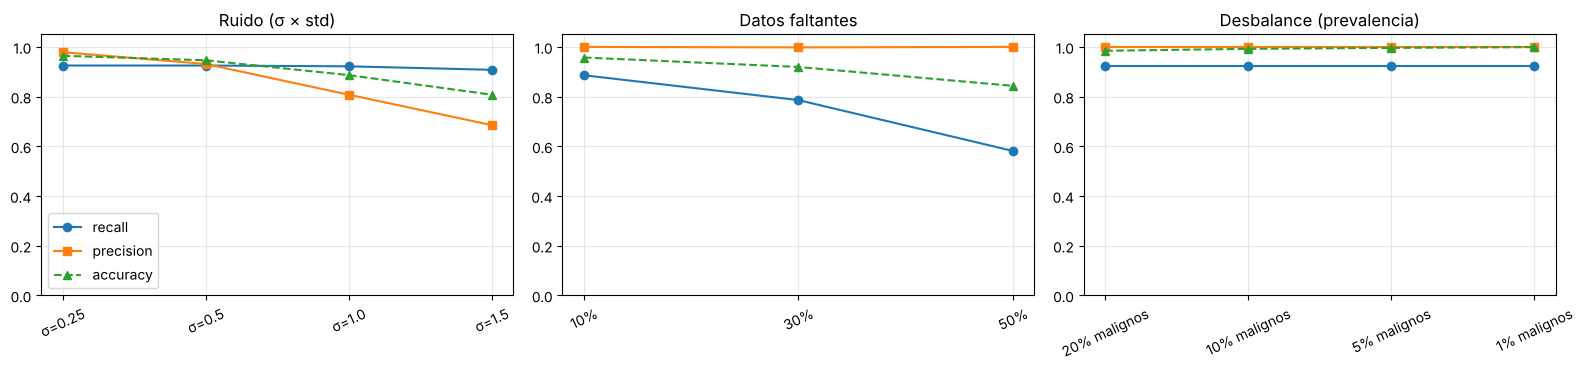

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, esc, titulo in zip(axes, ["Ruido", "Faltantes", "Desbalance"],
                           ["Ruido (σ × std)", "Datos faltantes", "Desbalance (prevalencia)"]):
    sub = df[df["escenario"] == esc]
    ax.plot(sub["nivel"], sub["recall"], "o-", label="recall")
    ax.plot(sub["nivel"], sub["precision"], "s-", label="precision")
    ax.plot(sub["nivel"], sub["accuracy"], "^--", label="accuracy")
    ax.set_title(titulo); ax.set_ylim(0, 1.05); ax.tick_params(axis="x", rotation=25)
axes[0].legend()
plt.tight_layout(); plt.show()

**TAREA 1.** Responde en una celda de texto:
1. ¿Qué escenario degrada más el recall? ¿Cuál degrada más la precisión?
2. En el escenario C, ¿por qué la *accuracy* engaña?
3. En el escenario D, ¿cuál es la diferencia entre el subgrupo de referencia y el distinto, y qué harías en producción?
4. ¿Qué escenario falla el criterio de aceptación y qué mitigación propones (más datos, reentrenar, umbral distinto, monitoreo)?

**TAREA 2.** Diseña un escenario propio (por ejemplo, etiquetas ruidosas o un cambio de escala en una variable) y agrégalo a `resumen`.

In [ ]:
# TAREA 2: escribe aquí tu escenario propio
# def mi_escenario(param):
#     def f(X, y, rng):
#         ...
#         return X2, y2
#     return f
#
# resumen.append({"escenario": "Mi escenario", "nivel": "...", **evaluar_perturbado(modelo, mi_escenario(...))})

---
# Workshop 2 · Análisis de sensibilidad de hiperparámetros

**Pregunta guía:** ¿qué hiperparámetros merecen presupuesto de búsqueda y cuáles se pueden fijar?

**Método:** buscamos con Optuna (optimización bayesiana, TPE) usando validación cruzada **solo sobre train**, y luego analizamos las 60 pruebas con tres herramientas: importancia, partial dependence y efectos de interacción.

In [ ]:
import optuna
from optuna.visualization.matplotlib import (plot_optimization_history, plot_param_importances,
                                             plot_slice, plot_contour)
from sklearn.inspection import PartialDependenceDisplay

optuna.logging.set_verbosity(optuna.logging.WARNING)
cv_opt = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=SEED)

def construir(params):
    return make_pipeline(StandardScaler(), RandomForestClassifier(**params, random_state=SEED))

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 20, 300),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
    }
    return cross_val_score(construir(params), X_train, y_train, cv=cv_opt, scoring="f1").mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=60)
print("Mejor F1 (CV):", round(study.best_value, 4))
print("Mejores parámetros:", study.best_params)

Mejor F1 (CV): 0.929
Mejores parámetros: {'n_estimators': 293, 'max_depth': 15, 'min_samples_leaf': 1, 'max_features': 0.6973958498538264}


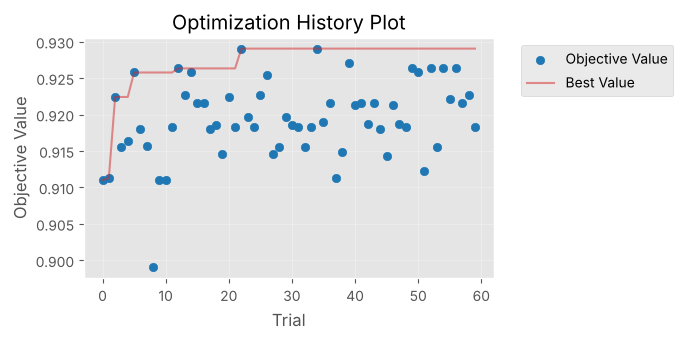

In [ ]:
ax = plot_optimization_history(study)
ax.figure.set_size_inches(7, 3.5); plt.show()

### 2.1 Importancia de hiperparámetros (*feature importance for hyperparameters*)
Optuna estima qué parámetros explican la variación del puntaje entre pruebas.

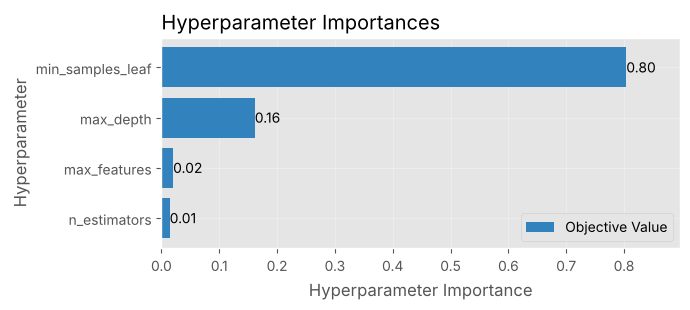

{'min_samples_leaf': 0.8039490111152061,
 'max_depth': 0.16148398959673727,
 'max_features': 0.02025531057163148,
 'n_estimators': 0.014311688716425248}

In [ ]:
ax = plot_param_importances(study)
ax.figure.set_size_inches(7, 3.2); plt.tight_layout(); plt.show()
optuna.importance.get_param_importances(study)

### 2.2 Efecto individual: slice y partial dependence plots
`plot_slice` muestra cada prueba. Para el *partial dependence* ajustamos un modelo sustituto (Random Forest) que predice el puntaje a partir de los hiperparámetros, y calculamos el efecto promedio de cada uno.

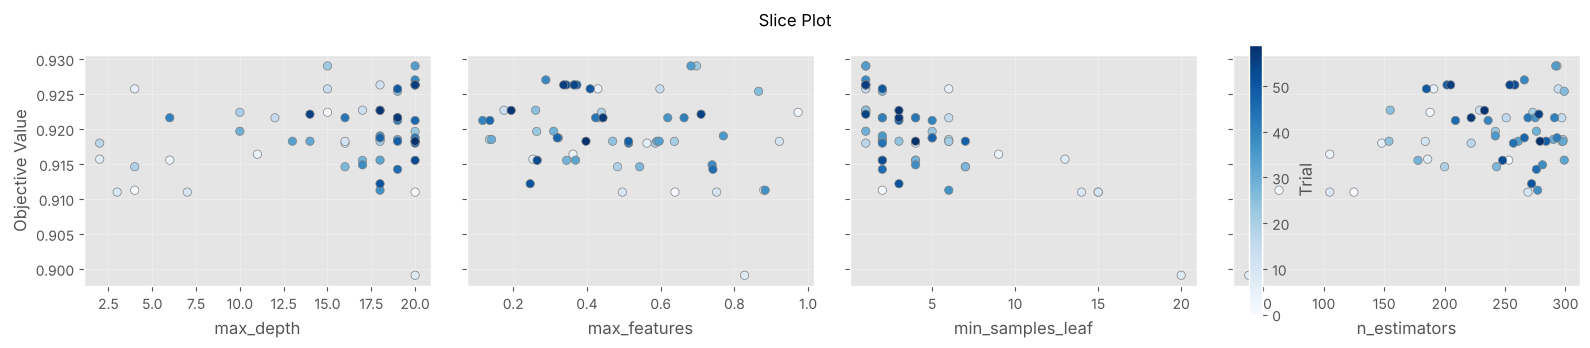

In [ ]:
axs = plot_slice(study)
fig = np.ravel(axs)[0].figure
fig.set_size_inches(16, 3.5); plt.tight_layout(); plt.show()

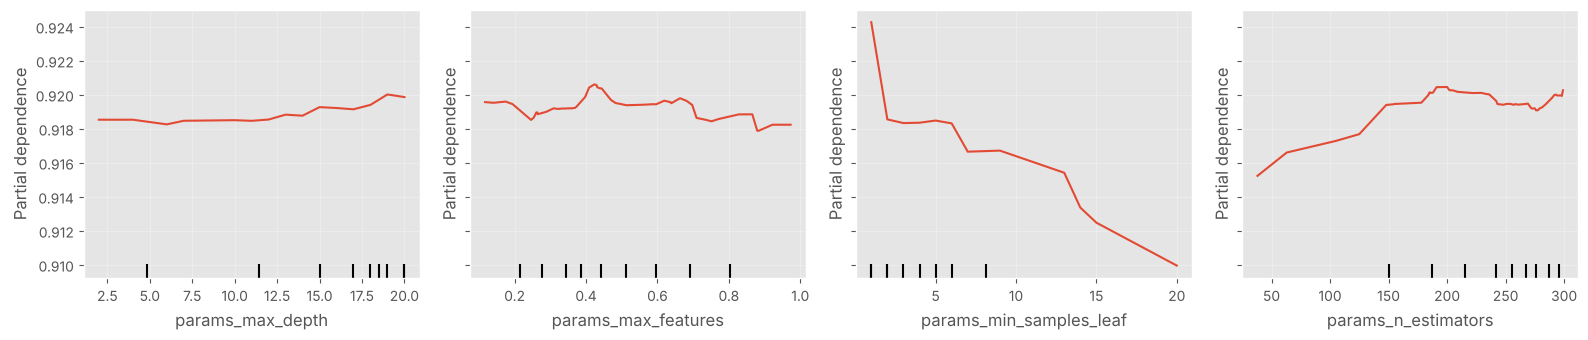

In [ ]:
df_t = study.trials_dataframe()
cols = [c for c in df_t.columns if c.startswith("params_")]
df_t[cols] = df_t[cols].astype(float)   # PDP no acepta columnas enteras
sustituto = RandomForestRegressor(n_estimators=300, random_state=SEED).fit(df_t[cols], df_t["value"])

fig, axs = plt.subplots(1, len(cols), figsize=(16, 3.5), sharey=True)
PartialDependenceDisplay.from_estimator(sustituto, df_t[cols], features=cols, ax=axs)
plt.tight_layout(); plt.show()

### 2.3 Efectos de interacción
Si el efecto de un parámetro depende del valor de otro, las curvas individuales no bastan. Miramos el contorno y la dependencia parcial en 2D para el par `max_depth` × `n_estimators`.

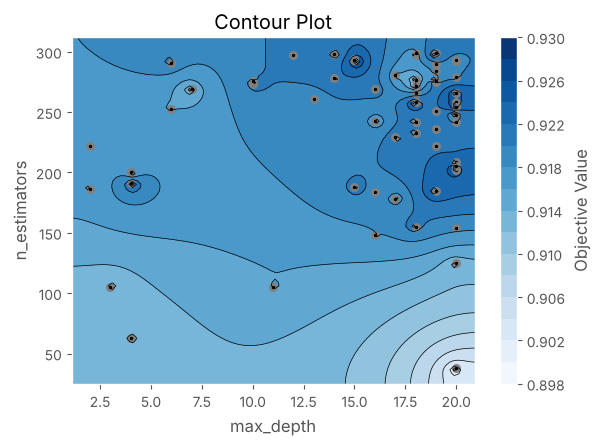

In [ ]:
ax = plot_contour(study, params=["max_depth", "n_estimators"])
ax.figure.set_size_inches(6.5, 4.5); plt.show()

**TAREA 3.** Con las figuras anteriores, responde:
1. ¿Qué hiperparámetros son importantes y cuáles no? ¿Las diferencias de F1 entre pruebas son grandes o pequeñas? (mira el eje vertical)
2. ¿Ves interacción entre `max_depth` y `n_estimators`, o los efectos son independientes?
3. ¿Qué rangos ampliarías y qué parámetros fijarías en tu informe?
4. ¿Por qué una diferencia de 0.002 en F1 entre dos configuraciones **no** justifica elegir una sobre otra? (conecta con el intervalo de confianza de la parte 0)

---
# Cierre · Evaluación final y validación del modelo optimizado
El test se usa **una sola vez**, al final, con el modelo ya elegido. Después repetimos la prueba de estrés del Workshop 1 sobre el modelo optimizado.

In [ ]:
modelo_opt = construir(study.best_params).fit(X_train, y_train)

final = pd.DataFrame({"baseline (200 árboles)": evaluar(modelo, X_test, y_test),
                      "optimizado (Optuna)": evaluar(modelo_opt, X_test, y_test)}).T
final.round(3)

,accuracy,recall,precision,f1,auc,auc_pr
baseline (200 árboles),0.971,0.922,1.0,0.959,0.996,0.994
optimizado (Optuna),0.959,0.891,1.0,0.942,0.995,0.992


In [ ]:
filas = []
for nombre, m in [("baseline", modelo), ("optimizado", modelo_opt)]:
    for escenario, f in [("sin perturbar", lambda X, y, rng: (X, y)),
                         ("ruido σ=1.0", ruido(1.0)),
                         ("faltantes 30%", faltantes(0.3)),
                         ("desbalance 5%", desbalance(0.05))]:
        filas.append({"modelo": nombre, "escenario": escenario, **evaluar_perturbado(m, f)})

(pd.DataFrame(filas)[["modelo", "escenario", "recall", "precision", "f1", "auc_pr"]]
   .pivot(index="escenario", columns="modelo", values=["recall", "precision"]).round(3))

recall            precision           
modelo        baseline optimizado  baseline optimizado
escenario                                             
desbalance 5%    0.922      0.891     1.000      1.000
faltantes 30%    0.786      0.812     0.998      0.992
ruido σ=1.0      0.922      0.928     0.808      0.752
sin perturbar    0.922      0.891     1.000      1.000